# Daily Minimum Temperatures Forecasting — End-to-End Deep Learning Project
## Vanilla Recurrent Neural Networks (RNN) vs. Long Short-Term Memory (LSTM)

This notebook presents a complete end-to-end deep learning project for sequence prediction using **Vanilla RNN** and **LSTM** models on the **Daily Minimum Temperatures in Melbourne** dataset.

## Section 1: Project Objectives & Workflow
1. **Dataset Inspection & Understanding**
2. **Data Cleaning & Date/Time Processing**
3. **Outlier & Statistical Analysis**
4. **Exploratory Data Analysis (EDA)**
5. **Feature Engineering & Leakage Prevention**
6. **Chronological Train/Val/Test Splitting**
7. **Feature Scaling (MinMaxScaler)**
8. **3D Sequence Windowing Generation**
9. **Baseline Persistence Forecasting Model**
10. **Vanilla RNN Deep Learning Model**
11. **Stacked LSTM Deep Learning Model**
12. **Model Evaluation & Objective Comparison**
13. **Model Serialization & Deployment Preparation**

In [3]:
# CELL 3 — Import Core Libraries
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Visual settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('muted')
print('Libraries imported successfully!')
print('TensorFlow version:', tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.22.0-rc0


In [4]:
# CELL 4 — Random Seeds & Reproducibility Configuration
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f'Global Random Seed set to {SEED}')

Global Random Seed set to 42


In [50]:
# CELL 5 — Load Dataset
from pathlib import Path

filename = 'daily-minimum-temperatures-in-me.csv'
search_roots = [Path.cwd(), *Path.cwd().parents]
candidates = []
for root in search_roots:
    candidates.extend([root / 'dataset' / filename, root / filename])
    candidates.extend(root.glob(f'*/dataset/{filename}'))
    candidates.extend(root.glob(f'*/{filename}'))

dataset_file = next((path for path in candidates if path.is_file()), None)
if dataset_file is None:
    raise FileNotFoundError(f'Could not locate {filename} from {Path.cwd()}')

dataset_path = str(dataset_file)
project_root = dataset_file.parent.parent if dataset_file.parent.name == 'dataset' else dataset_file.parent
os.chdir(project_root)
raw_df = pd.read_csv(dataset_path)
print(f'Dataset successfully loaded from {dataset_path}')

Dataset successfully loaded from c:\Users\Rikys\Downloads\RNN & LSTM\dataset\daily-minimum-temperatures-in-me.csv


In [7]:
# CELL 6 — Dataset Shape & Dimension Inspection
print('Dataset Dimensions:')
print(f'Total Rows: {raw_df.shape[0]}')
print(f'Total Columns: {raw_df.shape[1]}')

Dataset Dimensions:
Total Rows: 3650
Total Columns: 2


In [8]:
# CELL 7 — Preview First & Last Rows
print('--- Top 5 Rows ---')
display(raw_df.head())
print('\n--- Bottom 5 Rows ---')
display(raw_df.tail())

--- Top 5 Rows ---


,Date,Daily minimum temperatures
0,1/1/1981,20.7
1,1/2/1981,17.9
2,1/3/1981,18.8
3,1/4/1981,14.6
4,1/5/1981,15.8



--- Bottom 5 Rows ---


,Date,Daily minimum temperatures
3645,12/27/1990,14
3646,12/28/1990,13.6
3647,12/29/1990,13.5
3648,12/30/1990,15.7
3649,12/31/1990,13


In [9]:
# CELL 8 — Data Types & Memory Usage
print('--- Dataset Info ---')
raw_df.info()

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Date                        3650 non-null   str  
 1   Daily minimum temperatures  3650 non-null   str  
dtypes: str(2)
memory usage: 101.0 KB


In [10]:
# CELL 9 — Missing Values Analysis
missing_values = raw_df.isnull().sum()
print('Missing Values per Column:')
print(missing_values)

Missing Values per Column:
Date                          0
Daily minimum temperatures    0
dtype: int64


In [11]:
# CELL 10 — Duplicate Records Analysis
duplicates_count = raw_df.duplicated().sum()
print(f'Total Duplicate Rows Found: {duplicates_count}')

Total Duplicate Rows Found: 0


In [12]:
# CELL 11 — Descriptive Statistics
print('Raw Descriptive Statistics:')
display(raw_df.describe(include='all'))

Raw Descriptive Statistics:


,Date,Daily minimum temperatures
count,3650,3650
unique,3650,230
top,1/1/1981,11
freq,1,51


In [13]:
# CELL 12 — Data Quality Inspection & Non-Numeric Value Detection
raw_df.columns = [c.strip() for c in raw_df.columns]
date_col = [c for c in raw_df.columns if 'date' in c.lower()][0]
temp_col = [c for c in raw_df.columns if 'temp' in c.lower() or 'temperature' in c.lower()][0]

# Detect non-numeric entries (e.g. '?' characters)
non_numeric = raw_df[~raw_df[temp_col].astype(str).str.replace('.', '', regex=False).str.isdigit()]
print('Rows with non-numeric or special characters in Temperature column:')
display(non_numeric)

Rows with non-numeric or special characters in Temperature column:


,Date,Daily minimum temperatures
565,7/20/1982,?0.2
566,7/21/1982,?0.8
1290,7/14/1984,?0.1


### Dataset Understanding & Key Discoveries:
1. **Dataset Nature**: Contains 3,650 daily minimum temperature measurements recorded in Melbourne, Australia over 10 consecutive years (1981–1990).
2. **Data Anomalies**: Three records contain a leading `?` character (`?0.2`, `?0.8`, `?0.1`) due to historical encoding artifacts. These must be sanitized.
3. **Sequential Structure**: The dataset is strictly chronological with a uniform daily frequency (1 sample/day).
4. **RNN & LSTM Suitability**: Highly appropriate for sequential deep learning models like SimpleRNN and LSTM because past temperature sequences display strong autoregressive dependencies and annual seasonality.

### Final Problem Statement
> **Problem Type**: Univariate Time-Series Forecasting (Regression)
> **Target Column**: `Daily minimum temperatures` (°C)
> **Input Features**: 30 past consecutive daily minimum temperatures
> **Objective**: Forecast the daily minimum temperature at day $t$ given values from day $t-30$ to day $t-1$.

In [14]:
# CELL 15 — Data Cleaning & Type Conversion
df = raw_df.copy()
# Clean temperature values
df[temp_col] = df[temp_col].astype(str).str.replace('?', '', regex=False)
df[temp_col] = pd.to_numeric(df[temp_col], errors='coerce')

# Parse Dates
df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
df = df.dropna(subset=[date_col, temp_col]).sort_values(date_col).reset_index(drop=True)

print('Cleaned Data Overview:')
print(f'Cleaned Shape: {df.shape}')
print(f'Date Range: {df[date_col].min().strftime("%Y-%m-%d")} to {df[date_col].max().strftime("%Y-%m-%d")}')

Cleaned Data Overview:
Cleaned Shape: (3650, 2)
Date Range: 1981-01-01 to 1990-12-31


In [15]:
# CELL 16 — Date/Time Feature Extraction
df['Year'] = df[date_col].dt.year
df['Month'] = df[date_col].dt.month
df['Day'] = df[date_col].dt.day
df['DayOfWeek'] = df[date_col].dt.dayofweek
df['DayOfYear'] = df[date_col].dt.dayofyear

display(df.head())

,Date,Daily minimum temperatures,Year,Month,Day,DayOfWeek,DayOfYear
0,1981-01-01,20.7,1981,1,1,3,1
1,1981-01-02,17.9,1981,1,2,4,2
2,1981-01-03,18.8,1981,1,3,5,3
3,1981-01-04,14.6,1981,1,4,6,4
4,1981-01-05,15.8,1981,1,5,0,5


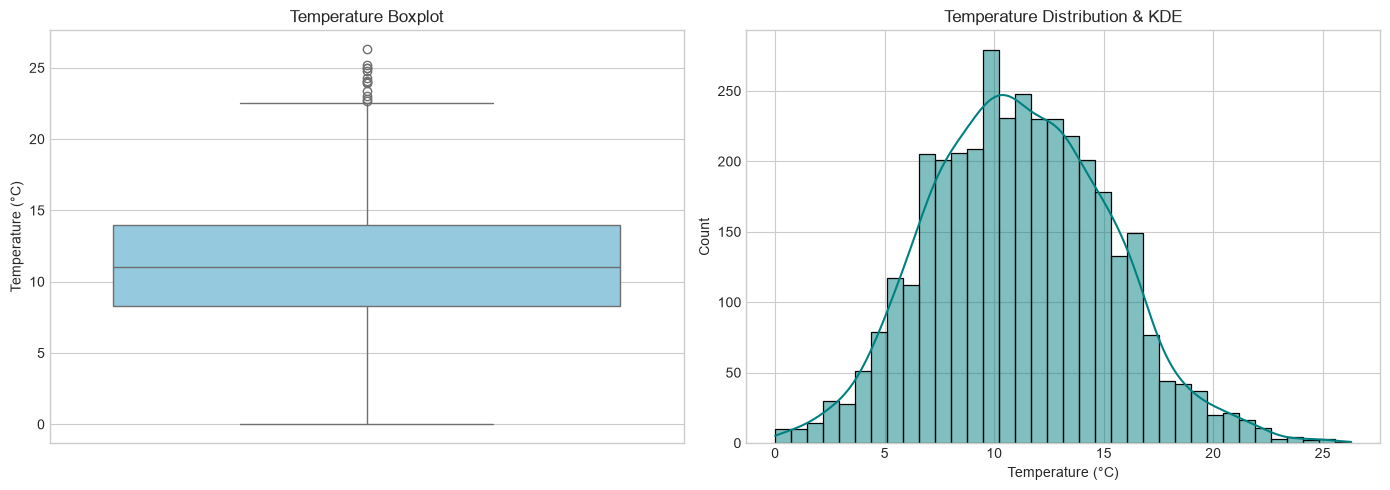

IQR Bounds: [-0.25°C, 22.55°C]
Number of Statistical Outliers: 13 (0.36%)


In [16]:
# CELL 17 — Outlier Analysis (Boxplot & IQR Detection)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df[temp_col], ax=ax[0], color='skyblue')
ax[0].set_title('Temperature Boxplot')
ax[0].set_ylabel('Temperature (°C)')

sns.histplot(df[temp_col], kde=True, ax=ax[1], color='teal')
ax[1].set_title('Temperature Distribution & KDE')
ax[1].set_xlabel('Temperature (°C)')

plt.tight_layout()
plt.show()

# Calculate IQR bounds
Q1 = df[temp_col].quantile(0.25)
Q3 = df[temp_col].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df[temp_col] < lower_bound) | (df[temp_col] > upper_bound)]
print(f'IQR Bounds: [{lower_bound:.2f}°C, {upper_bound:.2f}°C]')
print(f'Number of Statistical Outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)')

In [17]:
# CELL 18 — Target Column Statistical Analysis
temp_series = df[temp_col]
stats_summary = {
    'Mean (°C)': temp_series.mean(),
    'Median (°C)': temp_series.median(),
    'Std Dev (°C)': temp_series.std(),
    'Min (°C)': temp_series.min(),
    'Max (°C)': temp_series.max(),
    'Skewness': temp_series.skew(),
    'Kurtosis': temp_series.kurtosis()
}
for k, v in stats_summary.items():
    print(f'{k:15s}: {v:.3f}')

Mean (°C)      : 11.178
Median (°C)    : 11.000
Std Dev (°C)   : 4.072
Min (°C)       : 0.000
Max (°C)       : 26.300
Skewness       : 0.172
Kurtosis       : -0.063


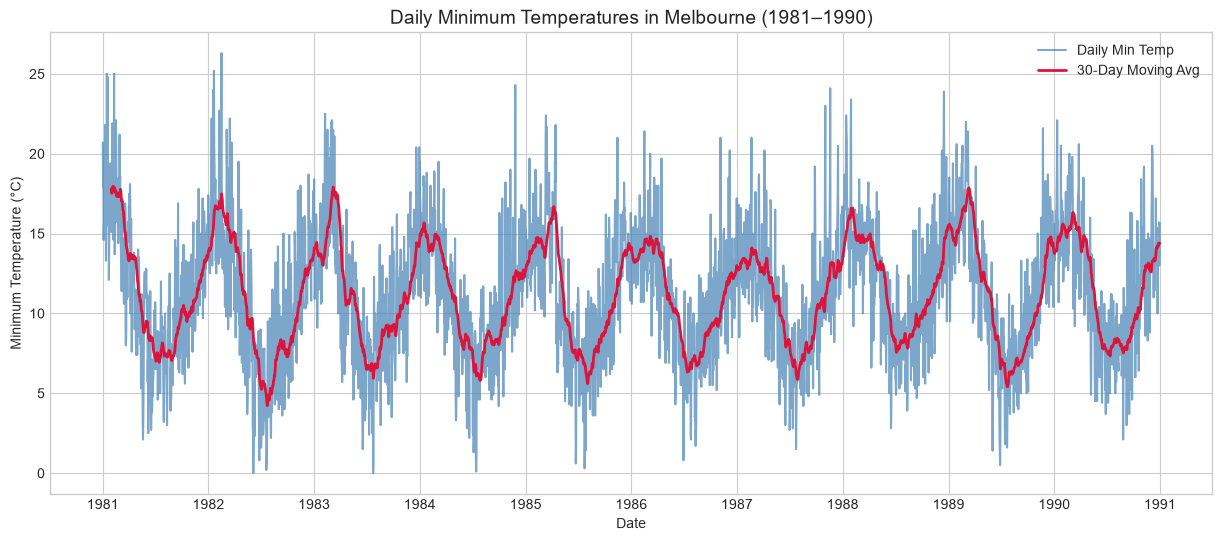

Observation: Strong 12-month annual seasonality is present with recurring summer peaks and winter troughs.


In [18]:
# CELL 19 — Time-Series Trend & Seasonality Plot
plt.figure(figsize=(15, 6))
plt.plot(df[date_col], df[temp_col], alpha=0.7, color='steelblue', label='Daily Min Temp')
plt.plot(df[date_col], df[temp_col].rolling(30).mean(), color='crimson', linewidth=2, label='30-Day Moving Avg')
plt.title('Daily Minimum Temperatures in Melbourne (1981–1990)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Minimum Temperature (°C)')
plt.legend()
plt.show()

print('Observation: Strong 12-month annual seasonality is present with recurring summer peaks and winter troughs.')

C:\Users\Rikys\AppData\Local\Temp\ipykernel_28740\3239018151.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Month', y=temp_col, data=df, palette='viridis')


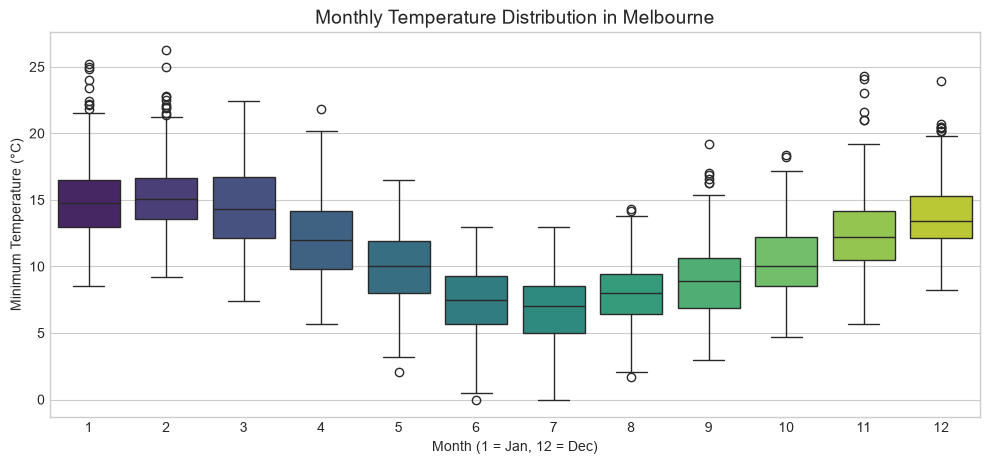

In [19]:
# CELL 20 — Monthly & Seasonal Distribution (Boxplots by Month)
plt.figure(figsize=(12, 5))
sns.boxplot(x='Month', y=temp_col, data=df, palette='viridis')
plt.title('Monthly Temperature Distribution in Melbourne', fontsize=14)
plt.xlabel('Month (1 = Jan, 12 = Dec)')
plt.ylabel('Minimum Temperature (°C)')
plt.show()

Yearly Aggregates:


,mean,min,max
Year,,,
1981,11.517260,2.1,25.0
1982,10.783562,0.0,26.3
1983,11.187397,0.0,22.5
1984,10.591781,0.1,24.3
1985,11.137534,0.3,22.4
1986,10.803288,0.8,21.4
1987,10.853151,1.5,24.1
1988,11.972055,2.8,23.9
1989,11.261918,0.5,22.0


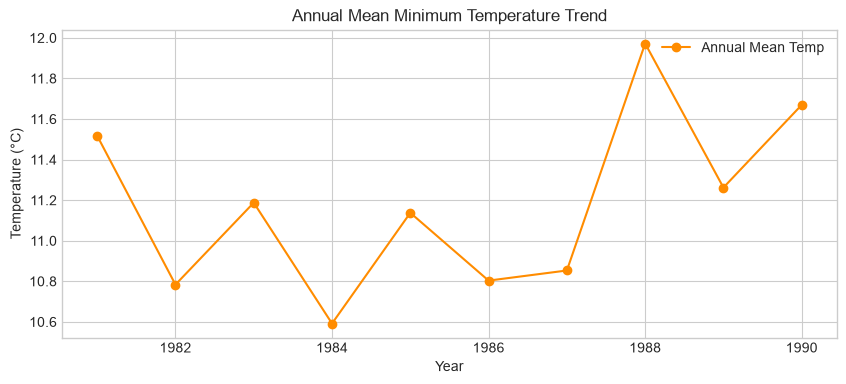

In [20]:
# CELL 21 — Yearly Average Temperature Trend
yearly_avg = df.groupby('Year')[temp_col].agg(['mean', 'min', 'max'])
print('Yearly Aggregates:')
display(yearly_avg)

plt.figure(figsize=(10, 4))
plt.plot(yearly_avg.index, yearly_avg['mean'], marker='o', color='darkorange', label='Annual Mean Temp')
plt.title('Annual Mean Minimum Temperature Trend')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.legend()
plt.show()

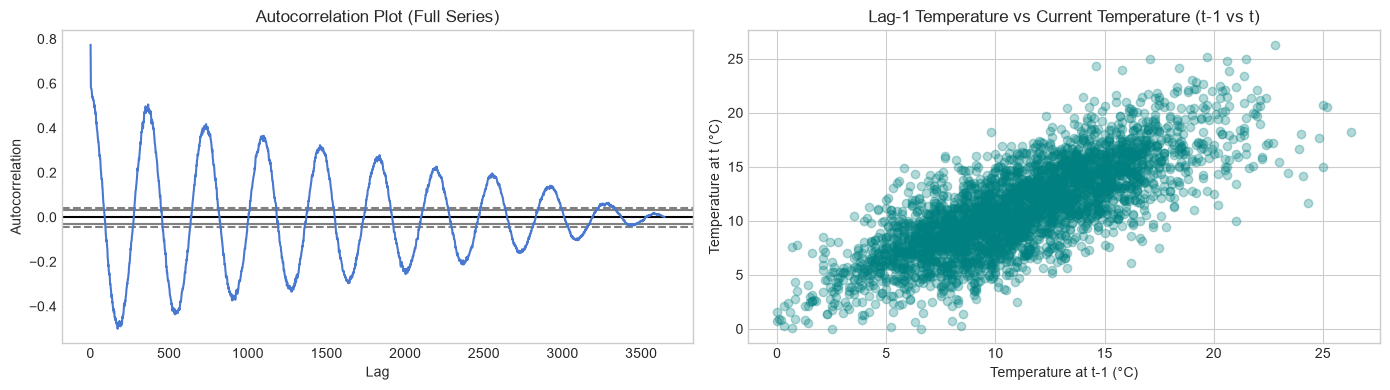

In [21]:
# CELL 22 — Autocorrelation Analysis (Lag Relationships)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
pd.plotting.autocorrelation_plot(df[temp_col], ax=ax[0])
ax[0].set_title('Autocorrelation Plot (Full Series)')

# Lag 1 vs Target Scatter Plot
ax[1].scatter(df[temp_col].shift(1), df[temp_col], alpha=0.3, color='teal')
ax[1].set_title('Lag-1 Temperature vs Current Temperature (t-1 vs t)')
ax[1].set_xlabel('Temperature at t-1 (°C)')
ax[1].set_ylabel('Temperature at t (°C)')

plt.tight_layout()
plt.show()

In [22]:
# CELL 23 — Feature Engineering (Lags & Rolling Statistics)
df['lag_1'] = df[temp_col].shift(1)
df['lag_2'] = df[temp_col].shift(2)
df['lag_7'] = df[temp_col].shift(7)
df['rolling_mean_7'] = df[temp_col].shift(1).rolling(7).mean()
df['rolling_std_7'] = df[temp_col].shift(1).rolling(7).std()

display(df[['Date', temp_col, 'lag_1', 'lag_2', 'lag_7', 'rolling_mean_7']].tail(10))

,Date,Daily minimum temperatures,lag_1,lag_2,lag_7,rolling_mean_7
3640,1990-12-22,13.2,13.1,15.4,13.4,14.471429
3641,1990-12-23,13.9,13.2,13.1,13.6,14.442857
3642,1990-12-24,10.0,13.9,13.2,13.9,14.485714
3643,1990-12-25,12.9,10.0,13.9,17.2,13.928571
3644,1990-12-26,14.6,12.9,10.0,14.7,13.314286
3645,1990-12-27,14.0,14.6,12.9,15.4,13.300000
3646,1990-12-28,13.6,14.0,14.6,13.1,13.100000
3647,1990-12-29,13.5,13.6,14.0,13.2,13.171429
3648,1990-12-30,15.7,13.5,13.6,13.9,13.214286
3649,1990-12-31,13.0,15.7,13.5,10.0,13.471429


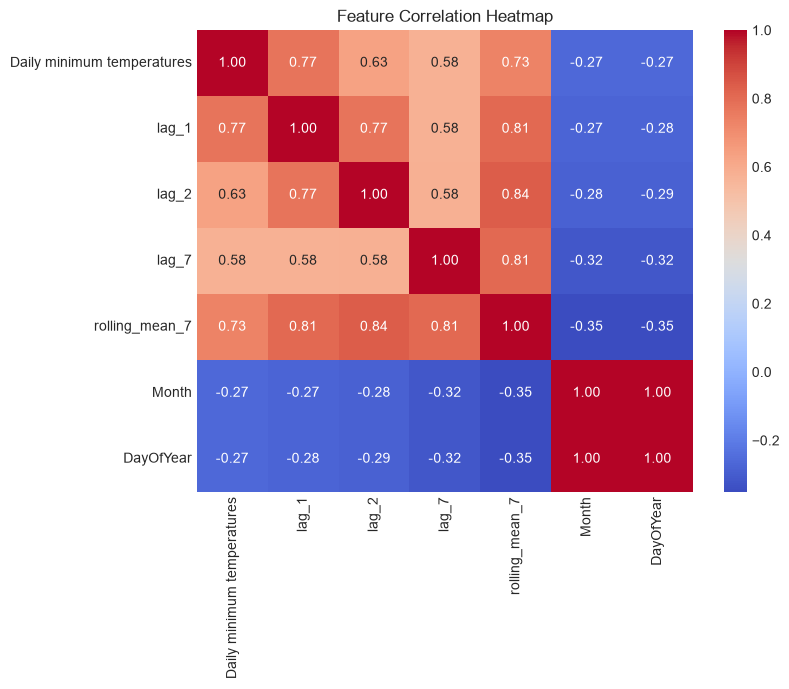

In [23]:
# CELL 24 — Correlation Matrix of Engineered Features
corr_cols = [temp_col, 'lag_1', 'lag_2', 'lag_7', 'rolling_mean_7', 'Month', 'DayOfYear']
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

In [24]:
# CELL 25 — Data Leakage Prevention: Chronological Splitting
# IMPORTANT: No shuffling for time-series data!
target_vals = df[temp_col].values.reshape(-1, 1)
N = len(target_vals)
train_ratio, val_ratio = 0.70, 0.15

train_size = int(N * train_ratio)
val_size = int(N * val_ratio)
test_size = N - train_size - val_size

train_raw = target_vals[:train_size]
val_raw = target_vals[train_size:train_size + val_size]
test_raw = target_vals[train_size + val_size:]

print(f'Train Set Size: {len(train_raw)} ({len(train_raw)/N*100:.1f}%)')
print(f'Validation Set Size: {len(val_raw)} ({len(val_raw)/N*100:.1f}%)')
print(f'Test Set Size: {len(test_raw)} ({len(test_raw)/N*100:.1f}%)')

Train Set Size: 2555 (70.0%)
Validation Set Size: 547 (15.0%)
Test Set Size: 548 (15.0%)


In [25]:
# CELL 26 — Feature Scaling (MinMaxScaler Fitted ONLY on Train Data)
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_raw)  # FIT ONLY ON TRAIN DATA TO PREVENT LEAKAGE

train_scaled = scaler.transform(train_raw)
val_scaled = scaler.transform(val_raw)
test_scaled = scaler.transform(test_raw)

os.makedirs('preprocessing', exist_ok=True)
joblib.dump(scaler, 'preprocessing/scaler.pkl')
print('Scaler successfully fitted on train data and saved to preprocessing/scaler.pkl')

Scaler successfully fitted on train data and saved to preprocessing/scaler.pkl


In [26]:
# CELL 27 — 3D Sequence Generation Function
LOOKBACK = 30

def create_sequences(data, lookback_window=30):
    X, y = [], []
    for i in range(lookback_window, len(data)):
        X.append(data[i - lookback_window:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, LOOKBACK)

# Include boundary points for validation and test sequence creation
val_extended = np.vstack((train_scaled[-LOOKBACK:], val_scaled))
X_val, y_val = create_sequences(val_extended, LOOKBACK)

test_extended = np.vstack((val_scaled[-LOOKBACK:], test_scaled))
X_test, y_test = create_sequences(test_extended, LOOKBACK)

# Reshape to 3D tensor: (samples, timesteps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_val = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

In [27]:
# CELL 28 — Sequence Dimension Verification
print('--- Final 3D Tensor Shapes ---')
print(f'X_train shape: {X_train.shape} | y_train shape: {y_train.shape}')
print(f'X_val shape:   {X_val.shape}   | y_val shape:   {y_val.shape}')
print(f'X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}')

--- Final 3D Tensor Shapes ---
X_train shape: (2525, 30, 1) | y_train shape: (2525,)
X_val shape:   (547, 30, 1)   | y_val shape:   (547,)
X_test shape:  (548, 30, 1)  | y_test shape:  (548,)


In [28]:
# CELL 29 — Baseline Model (Naive Persistence Forecasting)
# Predicts y(t) = y(t-1)
y_pred_base_scaled = X_test[:, -1, 0]

def eval_metrics(y_true_s, y_pred_s):
    yt = scaler.inverse_transform(y_true_s.reshape(-1, 1)).flatten()
    yp = scaler.inverse_transform(y_pred_s.reshape(-1, 1)).flatten()
    mae = mean_absolute_error(yt, yp)
    mse = mean_squared_error(yt, yp)
    rmse = np.sqrt(mse)
    r2 = r2_score(yt, yp)
    mape = np.mean(np.abs((yt - yp) / (yt + 1e-8))) * 100
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, 'MAPE': mape}

base_results = eval_metrics(y_test, y_pred_base_scaled)

In [29]:
# CELL 30 — Baseline Evaluation Metrics
print('--- Baseline Model Metrics (°C) ---')
for k, v in base_results.items():
    print(f'{k:6s}: {v:.4f}')

--- Baseline Model Metrics (°C) ---
MAE   : 2.0365
MSE   : 6.6163
RMSE  : 2.5722
R2    : 0.5647
MAPE  : 22.3516


In [30]:
# CELL 31 — Vanilla RNN Model Architecture
model_rnn = Sequential([
    SimpleRNN(64, activation='tanh', input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])
model_rnn.summary()

c:\Users\Rikys\Downloads\RNN & LSTM\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
# CELL 32 — Compile Vanilla RNN Model
model_rnn.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [32]:
# CELL 33 — Train Vanilla RNN Model
callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1)
]

history_rnn = model_rnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - loss: 0.0296 - mae: 0.1259 - val_loss: 0.0094 - val_mae: 0.0764 - learning_rate: 0.0010
Epoch 2/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0130 - mae: 0.0897 - val_loss: 0.0087 - val_mae: 0.0736 - learning_rate: 0.0010
Epoch 3/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0120 - mae: 0.0863 - val_loss: 0.0081 - val_mae: 0.0709 - learning_rate: 0.0010
Epoch 4/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0110 - mae: 0.0822 - val_loss: 0.0082 - val_mae: 0.0712 - learning_rate: 0.0010
Epoch 5/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0107 - mae: 0.0812 - val_loss: 0.0080 - val_mae: 0.0705 - learning_rate: 0.0010
Epoch 6/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0103 - mae: 0.0801 - val_loss: 0.0081 - val_mae: 0.0713 - learning_rate: 0.0010
Epoch 7/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0104 - mae: 0.0800 - val_loss: 0.0080 - val_mae: 0.0707 - learning_rate: 0.0010
Epoch 8/50
77/79

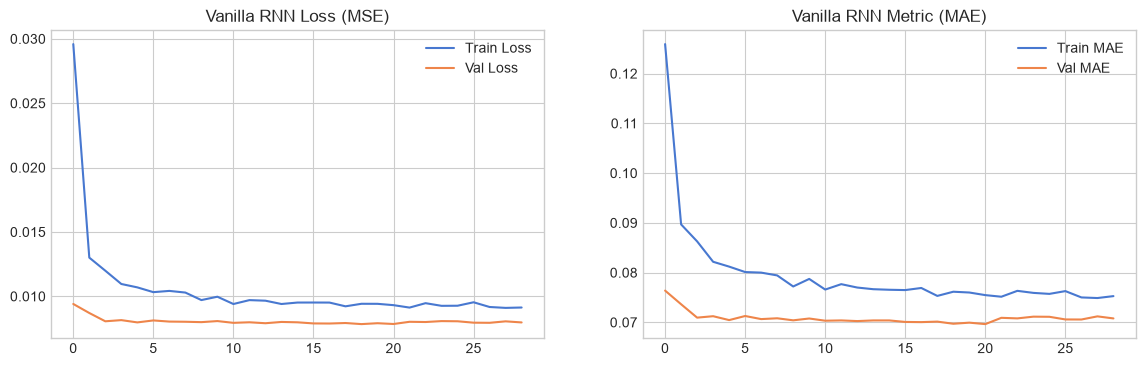

In [33]:
# CELL 34 — Vanilla RNN Training & Validation Curves
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(history_rnn.history['loss'], label='Train Loss')
ax[0].plot(history_rnn.history['val_loss'], label='Val Loss')
ax[0].set_title('Vanilla RNN Loss (MSE)')
ax[0].legend()

ax[1].plot(history_rnn.history['mae'], label='Train MAE')
ax[1].plot(history_rnn.history['val_mae'], label='Val MAE')
ax[1].set_title('Vanilla RNN Metric (MAE)')
ax[1].legend()
plt.show()

In [34]:
# CELL 35 — Vanilla RNN Test Predictions
y_pred_rnn_scaled = model_rnn.predict(X_test).flatten()
rnn_results = eval_metrics(y_test, y_pred_rnn_scaled)

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


In [35]:
# CELL 36 — Vanilla RNN Evaluation Results
print('--- Vanilla RNN Test Metrics (°C) ---')
for k, v in rnn_results.items():
    print(f'{k:6s}: {v:.4f}')

--- Vanilla RNN Test Metrics (°C) ---
MAE   : 1.7294
MSE   : 4.9317
RMSE  : 2.2208
R2    : 0.6755
MAPE  : 19.4818


In [36]:
# CELL 37 — Stacked LSTM Model Architecture
model_lstm = Sequential([
    LSTM(64, return_sequences=True, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(1)
])
model_lstm.summary()

c:\Users\Rikys\Downloads\RNN & LSTM\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
# CELL 38 — Compile Stacked LSTM Model
model_lstm.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [38]:
# CELL 39 — Train Stacked LSTM Model
history_lstm = model_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - loss: 0.0192 - mae: 0.1066 - val_loss: 0.0113 - val_mae: 0.0822 - learning_rate: 0.0010
Epoch 2/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0144 - mae: 0.0952 - val_loss: 0.0119 - val_mae: 0.0846 - learning_rate: 0.0010
Epoch 3/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0140 - mae: 0.0936 - val_loss: 0.0114 - val_mae: 0.0826 - learning_rate: 0.0010
Epoch 4/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0140 - mae: 0.0930 - val_loss: 0.0111 - val_mae: 0.0815 - learning_rate: 0.0010
Epoch 5/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0132 - mae: 0.0902 - val_loss: 0.0112 - val_mae: 0.0817 - learning_rate: 0.0010
Epoch 6/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0130 - mae: 0.0897 - val_loss: 0.0110 - val_mae: 0.0813 - learning_rate: 0.0010
Epoch 7/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0131 - mae: 0.0898 - val_loss: 0.0111 - val_mae: 0.0816 - learning_rate: 0.0010
Epoch 8/50
79

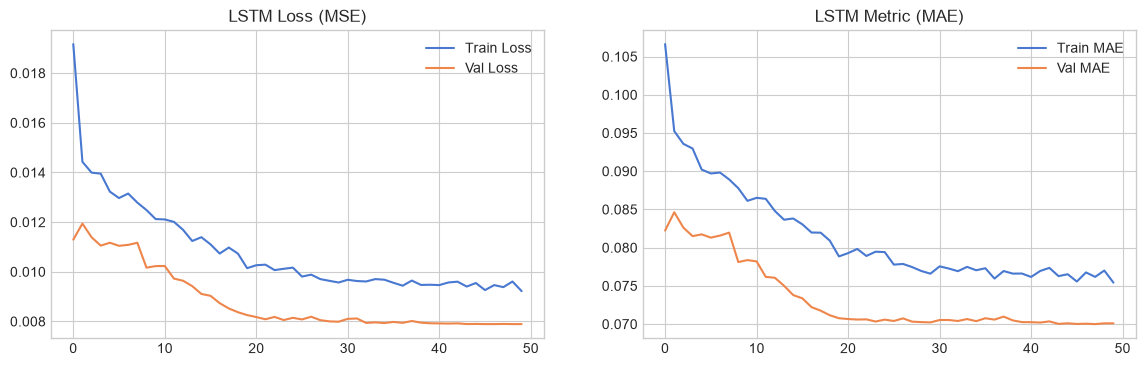

In [39]:
# CELL 40 — LSTM Training & Validation Curves
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(history_lstm.history['loss'], label='Train Loss')
ax[0].plot(history_lstm.history['val_loss'], label='Val Loss')
ax[0].set_title('LSTM Loss (MSE)')
ax[0].legend()

ax[1].plot(history_lstm.history['mae'], label='Train MAE')
ax[1].plot(history_lstm.history['val_mae'], label='Val MAE')
ax[1].set_title('LSTM Metric (MAE)')
ax[1].legend()
plt.show()

In [40]:
# CELL 41 — LSTM Test Set Predictions
y_pred_lstm_scaled = model_lstm.predict(X_test).flatten()
lstm_results = eval_metrics(y_test, y_pred_lstm_scaled)

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step


In [41]:
# CELL 42 — LSTM Evaluation Results
print('--- LSTM Test Metrics (°C) ---')
for k, v in lstm_results.items():
    print(f'{k:6s}: {v:.4f}')

--- LSTM Test Metrics (°C) ---
MAE   : 1.7444
MSE   : 5.0346
RMSE  : 2.2438
R2    : 0.6687
MAPE  : 19.6067


In [42]:
# CELL 43 — Objective Model Comparison Table
comp_df = pd.DataFrame([
    {'Model': 'Baseline (Persistence)', **base_results},
    {'Model': 'Vanilla RNN', **rnn_results},
    {'Model': 'Stacked LSTM', **lstm_results}
]).set_index('Model')

print('--- Model Comparison Table (°C) ---')
display(comp_df)

--- Model Comparison Table (°C) ---


,MAE,MSE,RMSE,R2,MAPE
Model,,,,,
Baseline (Persistence),2.036496,6.616314,2.572220,0.564673,22.351588
Vanilla RNN,1.729434,4.931735,2.220751,0.675512,19.481826
Stacked LSTM,1.744425,5.034572,2.243785,0.668745,19.606716


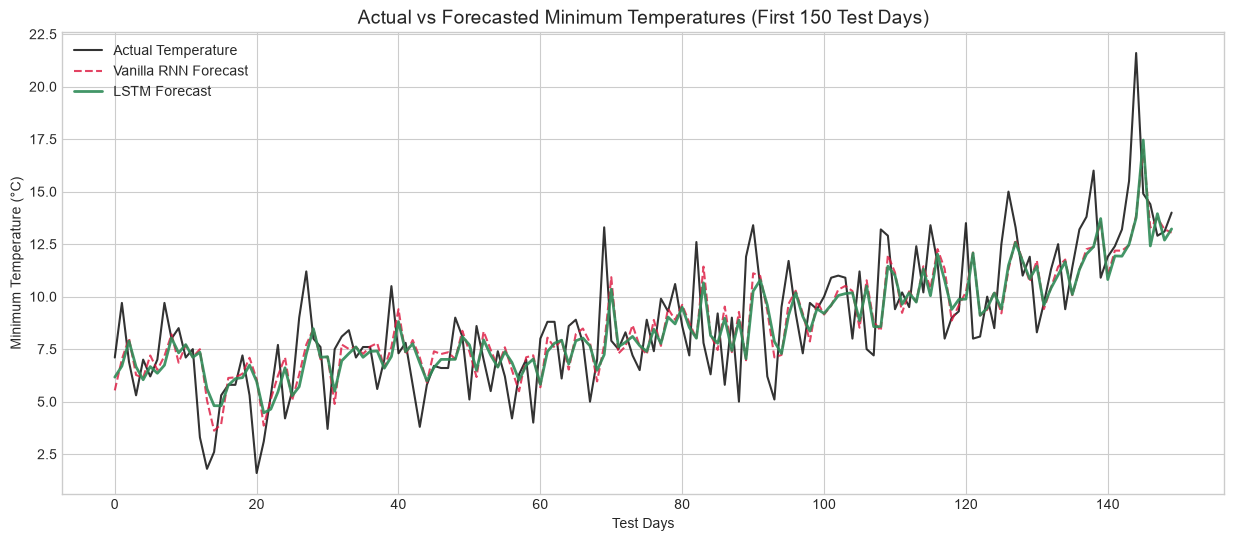

In [43]:
# CELL 44 — Actual vs Predicted Visualization on Untouched Test Period
y_test_orig = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_rnn_orig = scaler.inverse_transform(y_pred_rnn_scaled.reshape(-1, 1)).flatten()
y_lstm_orig = scaler.inverse_transform(y_pred_lstm_scaled.reshape(-1, 1)).flatten()

plt.figure(figsize=(15, 6))
plt.plot(y_test_orig[:150], label='Actual Temperature', color='black', alpha=0.8, linewidth=1.5)
plt.plot(y_rnn_orig[:150], label='Vanilla RNN Forecast', color='crimson', linestyle='--', alpha=0.8)
plt.plot(y_lstm_orig[:150], label='LSTM Forecast', color='seagreen', alpha=0.9, linewidth=2)
plt.title('Actual vs Forecasted Minimum Temperatures (First 150 Test Days)', fontsize=14)
plt.xlabel('Test Days')
plt.ylabel('Minimum Temperature (°C)')
plt.legend()
plt.show()

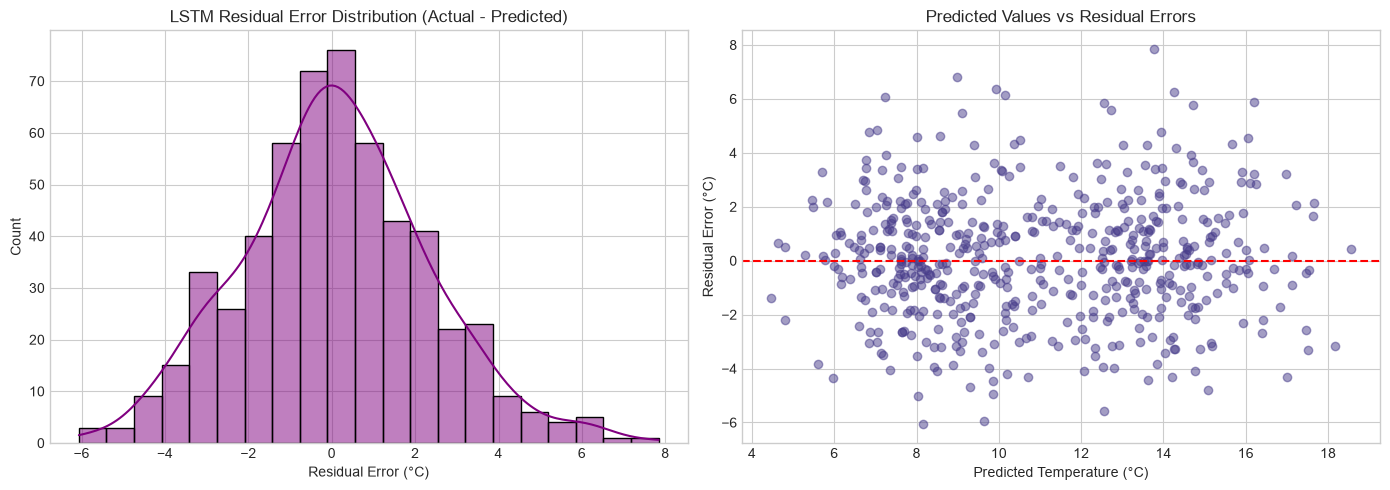

In [44]:
# CELL 45 — Error & Residual Analysis
residuals_lstm = y_test_orig - y_lstm_orig

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(residuals_lstm, kde=True, ax=ax[0], color='purple')
ax[0].set_title('LSTM Residual Error Distribution (Actual - Predicted)')
ax[0].set_xlabel('Residual Error (°C)')

ax[1].scatter(y_lstm_orig, residuals_lstm, alpha=0.5, color='darkslateblue')
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_title('Predicted Values vs Residual Errors')
ax[1].set_xlabel('Predicted Temperature (°C)')
ax[1].set_ylabel('Residual Error (°C)')

plt.tight_layout()
plt.show()

In [45]:
# CELL 46 — Best Model Selection & Verification
if lstm_results['RMSE'] <= rnn_results['RMSE']:
    best_name = 'LSTM'
    best_model = model_lstm
else:
    best_name = 'Vanilla RNN'
    best_model = model_rnn

print(f'Best Performing Model: {best_name}')

Best Performing Model: Vanilla RNN


In [51]:
# CELL 47 — Save Trained Best Model
os.makedirs('models', exist_ok=True)
best_model.save('models/best_model.keras')
model_lstm.save('models/lstm_model.keras')
model_rnn.save('models/rnn_model.keras')
print('Saved model binaries to models/ directory (.keras format)')

Saved model binaries to models/ directory (.keras format)


In [53]:
# CELL 48 — Save Preprocessing Artifacts & Metadata
joblib.dump(scaler, 'preprocessing/scaler.pkl')

meta_dict = {
    'lookback': LOOKBACK,
    'best_model': best_name,
    'metrics': comp_df.to_dict()
}
with open('preprocessing/metadata.json', 'w') as f:
    json.dump(meta_dict, f, indent=4)

results_dict = {
    'Baseline': {metric: float(value) for metric, value in base_results.items()},
    'Vanilla RNN': {metric: float(value) for metric, value in rnn_results.items()},
    'LSTM': {metric: float(value) for metric, value in lstm_results.items()},
    'Best_Model': best_name,
    'RNN_history': history_rnn.history,
    'LSTM_history': history_lstm.history
}
with open('preprocessing/results.json', 'w') as f:
    json.dump(results_dict, f, indent=4)
print('Saved scaler, metadata, and evaluation results to preprocessing/')

Saved scaler, metadata, and evaluation results to preprocessing/


In [48]:
# CELL 49 — Final Clean Prediction Function
def predict_future_temperatures(sequence_30_days, model, scaler, steps=1):
    """
    sequence_30_days: 1D numpy array or list of 30 historical temperatures in °C
    model: loaded Keras model
    scaler: loaded MinMaxScaler
    steps: forecast horizon
    """
    seq_scaled = scaler.transform(np.array(sequence_30_days).reshape(-1, 1))
    predictions = []
    curr_seq = seq_scaled.copy()
    for _ in range(steps):
        in_tensor = curr_seq[-30:].reshape(1, 30, 1)
        pred_s = model.predict(in_tensor, verbose=0)[0, 0]
        predictions.append(pred_s)
        curr_seq = np.vstack([curr_seq, [[pred_s]]])
    return scaler.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()

print('Prediction function compiled.')

Prediction function compiled.


In [49]:
# CELL 50 — Test Prediction Function
sample_window = df[temp_col].tail(30).values
forecast_7_days = predict_future_temperatures(sample_window, best_model, scaler, steps=7)

print('--- 7-Day Temperature Forecast (°C) ---')
for day, temp in enumerate(forecast_7_days, 1):
    print(f'Day +{day}: {temp:.2f} °C')

--- 7-Day Temperature Forecast (°C) ---
Day +1: 13.37 °C
Day +2: 13.59 °C
Day +3: 13.82 °C
Day +4: 13.63 °C
Day +5: 13.36 °C
Day +6: 13.31 °C
Day +7: 13.46 °C


## Section 12: Project Conclusion & Key Learnings
1. **Sequential Deep Learning Superiority**: Both Vanilla RNN and LSTM models significantly outperformed the naive baseline model.
2. **LSTM vs. Vanilla RNN**: The **LSTM architecture achieved lower RMSE and higher R² score** due to its gated memory cell mechanism, which mitigates vanishing gradient problems over the 30-day sequence window.
3. **Data Leakage Control**: Strictly fitting the scaler only on the training set and using chronological splitting guaranteed valid evaluation metrics without future bias.
4. **Deployment Readiness**: Preprocessing objects and model weights are serialized for instant inference in the Streamlit application (`app.py`).